# IEEE-CIS E-Commerce Fraud Detection & Risk Scoring

## Notebook 02 — Feature Engineering and Modeling

### Objective

This notebook develops and selects the fraud-ranking model using the
chronological development protocol defined in Notebook 01.

The workflow covers:

- reconstruction of the modeling dataset;
- leakage-safe categorical preprocessing;
- a LightGBM baseline;
- targeted feature-engineering experiments;
- feature-family ablation;
- controlled model refinement and selection.

Model development uses only days **1–127**. The later post-development and
final-holdout periods are not used for feature-engineering or model-selection
decisions.

Throughout this notebook, `pr_auc` refers to average precision calculated with
`average_precision_score`.

## 1. Environment and Data Reconstruction

Notebook 02 is self-contained. The two IEEE-CIS training tables are downloaded
again and the same deterministic preprocessing established in Notebook 01 is
reproduced.

Exploratory analysis is not repeated here. The purpose of this section is only
to reconstruct the modeling dataset and chronological development split.

In [1]:
!pip -q install -U kaggle lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 43.0 MB/s eta 0:00:00


In [2]:
from pathlib import Path
import gc
import os
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import userdata

import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [3]:
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [4]:
REPO_ROOT = Path(
    "/content/ecommerce-fraud-risk-ieee-cis"
)

FIGURES_DIR = (
    REPO_ROOT
    / "reports"
    / "figures"
)

TABLES_DIR = (
    REPO_ROOT
    / "reports"
    / "tables"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DATA_DIR = Path("/content/data/raw")
DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

COMPETITION = "ieee-fraud-detection"

files_to_download = [
    "train_transaction.csv",
    "train_identity.csv"
]

for filename in files_to_download:
    subprocess.run(
        [
            "kaggle",
            "competitions",
            "download",
            COMPETITION,
            "-f",
            filename,
            "-p",
            str(DATA_DIR)
        ],
        check=True
    )

In [5]:
TRANSACTION_PATH = DATA_DIR / "train_transaction.csv.zip"
IDENTITY_PATH = DATA_DIR / "train_identity.csv.zip"

transactions = pd.read_csv(
    TRANSACTION_PATH,
    compression="zip"
)

identity = pd.read_csv(
    IDENTITY_PATH,
    compression="zip"
)

In [6]:
def reduce_numeric_memory(df):
    int_cols = df.select_dtypes(include=["int64"]).columns
    float_cols = df.select_dtypes(include=["float64"]).columns

    for col in int_cols:
        df[col] = pd.to_numeric(
            df[col],
            downcast="integer"
        )

    for col in float_cols:
        df[col] = pd.to_numeric(
            df[col],
            downcast="float"
        )

    return df

In [7]:
transactions = reduce_numeric_memory(transactions)
identity = reduce_numeric_memory(identity)

In [8]:
identity_ids = set(identity["TransactionID"])

In [9]:
df = transactions.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

In [10]:
df["has_identity"] = (
    df["TransactionID"]
    .isin(identity_ids)
    .astype("int8")
)

In [11]:
missingness_exclude = [
    "TransactionID",
    "isFraud",
    "has_identity"
]

missingness_cols = [
    col for col in df.columns
    if col not in missingness_exclude
]

df["missing_pct"] = (
    df[missingness_cols]
    .isna()
    .mean(axis=1)
    .mul(100)
    .astype("float32")
)

In [12]:
assert len(df) == 590_540
assert df["TransactionID"].is_unique
assert df["isFraud"].isna().sum() == 0
assert df.shape[1] == 436

print(
    f"Reconstructed modeling dataset: "
    f"{df.shape[0]:,} rows × {df.shape[1]} columns"
)

print("Dataset reconstruction validated.")

Reconstructed modeling dataset: 590,540 rows × 436 columns
Dataset reconstruction validated.


In [13]:
del transactions
del identity
del identity_ids

_ = gc.collect()

## 2. Chronological Development Split

Model development uses the same fixed time boundaries established in Notebook 01.

Days **1–101** are used for model fitting and days **102–127** for internal
temporal validation. Days **128–154** remain reserved for later calibration and
operating-decision work, while days **155–182** form the final holdout.

In [14]:
# Reproduce the relative-day index used in Notebook 01.

SECONDS_PER_DAY = 60*60*24

relative_day = (
    df["TransactionDT"] // SECONDS_PER_DAY
).astype("int16")

In [15]:
TRAIN_END_DAY = 101
VALID_END_DAY = 127
POST_DEV_END_DAY = 154
FINAL_HOLDOUT_END_DAY = 182

In [16]:
train_mask = (
    relative_day <= TRAIN_END_DAY
)

valid_mask = (
    (relative_day > TRAIN_END_DAY)
    & (relative_day <= VALID_END_DAY)
)

post_dev_mask = (
    (relative_day > VALID_END_DAY)
    & (relative_day <= POST_DEV_END_DAY)
)

final_holdout_mask = (
    relative_day > POST_DEV_END_DAY
)

In [17]:
# Verify the fixed chronological periods from Notebook 01.

assert train_mask.sum() == 356_216
assert valid_mask.sum() == 81_295
assert post_dev_mask.sum() == 74_487
assert final_holdout_mask.sum() == 78_542

assert (
    train_mask.astype("int8")
    + valid_mask.astype("int8")
    + post_dev_mask.astype("int8")
    + final_holdout_mask.astype("int8")
).eq(1).all()

assert relative_day.max() == FINAL_HOLDOUT_END_DAY

print("Chronological split reproduced and validated.")

Chronological split reproduced and validated.


## 3. Baseline Feature Matrix and Categorical Handling

`TransactionID` and the fraud target are excluded from the predictive feature
matrix.

Categorical vocabularies are learned from the training period only. Missing
values receive an explicit token, and categories first observed in later data
are mapped to `__UNSEEN__`.

In [18]:
# Defines the baseline model's feature matrix

ID_COL = "TransactionID"
TARGET = "isFraud"

excluded_cols = [
    ID_COL,
    TARGET
]

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
]

In [19]:
X_train = df.loc[
    train_mask,
    feature_cols
].copy()

y_train = df.loc[
    train_mask,
    TARGET
].copy()

X_valid = df.loc[
    valid_mask,
    feature_cols
].copy()

y_valid = df.loc[
    valid_mask,
    TARGET
].copy()

In [20]:
# Creates leakage-safe categorical handling

categorical_cols = (
    X_train
    .select_dtypes(
        include=["object", "string"]
    )
    .columns
    .tolist()
)

print(
    f"Categorical features: "
    f"{len(categorical_cols)}"
)

Categorical features: 31


In [21]:
MISSING_TOKEN = "__MISSING__"
UNSEEN_TOKEN = "__UNSEEN__"


def fit_category_schema(
    train_df,
    categorical_columns
):
    schema = {}

    for col in categorical_columns:

        observed = (
            train_df[col]
            .dropna()
            .astype("string")
            .unique()
        )

        observed = pd.Index(observed)

        if (
            MISSING_TOKEN in observed
            or UNSEEN_TOKEN in observed
        ):
            raise ValueError(
                f"Reserved category token already exists in {col}"
            )

        schema[col] = observed

    return schema

In [22]:
def apply_category_schema(
    frame,
    schema
):
    transformed = frame.copy()

    for col, known_categories in schema.items():

        values = (
            transformed[col]
            .astype("string")
        )

        missing_mask = values.isna()

        unseen_mask = (
            ~missing_mask
            & ~values.isin(known_categories)
        )

        values = values.mask(
            missing_mask,
            MISSING_TOKEN
        )

        values = values.mask(
            unseen_mask,
            UNSEEN_TOKEN
        )

        categories = (
            list(known_categories)
            + [
                MISSING_TOKEN,
                UNSEEN_TOKEN
            ]
        )

        transformed[col] = pd.Categorical(
            values,
            categories=categories
        )

    return transformed

In [23]:
category_schema = fit_category_schema(
    X_train,
    categorical_cols
)

In [24]:
X_train = apply_category_schema(
    X_train,
    category_schema
)

X_valid = apply_category_schema(
    X_valid,
    category_schema
)

## 4. Baseline LightGBM

The first model uses the full baseline feature matrix without additional feature
engineering.

LightGBM is used because it handles high-dimensional tabular data, native
missing values, and categorical features efficiently. Performance is evaluated
on the later internal-validation period.

In [25]:
# Creates the Baseline LightGBM model

BASELINE_MODEL_PARAMS = {
    "objective": "binary",
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": -1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.0,
    "reg_lambda": 0.0,
    "verbosity": -1,
    "random_state": 42,
    "n_jobs": -1
}

baseline_model = lgb.LGBMClassifier(
    **BASELINE_MODEL_PARAMS
)

In [26]:
baseline_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_valid, y_valid)
    ],
    eval_metric=[
        "auc",
        "average_precision"
    ],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100
        ),
        lgb.log_evaluation(
            period=100
        )
    ]
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.901612	valid_0's average_precision: 0.583427	valid_0's binary_logloss: 0.100593
[200]	valid_0's auc: 0.913972	valid_0's average_precision: 0.608054	valid_0's binary_logloss: 0.095418
[300]	valid_0's auc: 0.920258	valid_0's average_precision: 0.622344	valid_0's binary_logloss: 0.0929018
[400]	valid_0's auc: 0.923243	valid_0's average_precision: 0.630068	valid_0's binary_logloss: 0.0915557
[500]	valid_0's auc: 0.924893	valid_0's average_precision: 0.635489	valid_0's binary_logloss: 0.0906742
[600]	valid_0's auc: 0.926799	valid_0's average_precision: 0.638986	valid_0's binary_logloss: 0.0900627
[700]	valid_0's auc: 0.927462	valid_0's average_precision: 0.641782	valid_0's binary_logloss: 0.0896976
[800]	valid_0's auc: 0.927981	valid_0's average_precision: 0.643694	valid_0's binary_logloss: 0.0895161
[900]	valid_0's auc: 0.928294	valid_0's average_precision: 0.644997	valid_0's binary_logloss: 0.0895489
[100

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03, n_estimators=2000,
               n_jobs=-1, objective='binary', random_state=42, verbosity=-1)

In [27]:
# Baseline model evaluation


# Baseline predictions

valid_pred = baseline_model.predict_proba(
    X_valid
)[:, 1]

In [28]:
# Baseline evaluation metrics

baseline_roc_auc = roc_auc_score(
    y_valid,
    valid_pred
)

baseline_pr_auc = average_precision_score(
    y_valid,
    valid_pred
)

print(
    f"Validation ROC-AUC: "
    f"{baseline_roc_auc:.4f}"
)

print(
    f"Validation PR-AUC:  "
    f"{baseline_pr_auc:.4f}"
)

print(
    f"Best iteration:     "
    f"{baseline_model.best_iteration_}"
)

Validation ROC-AUC: 0.9288
Validation PR-AUC:  0.6466
Best iteration:     958


In [29]:
# Baseline model fraud prevalence and PR-AUC/prevalence lift

validation_prevalence = y_valid.mean()

print(
    f"Validation fraud prevalence: "
    f"{validation_prevalence:.4f}"
)

print(
    f"PR-AUC / prevalence lift: "
    f"{baseline_pr_auc / validation_prevalence:.1f}x"
)

Validation fraud prevalence: 0.0406
PR-AUC / prevalence lift: 15.9x


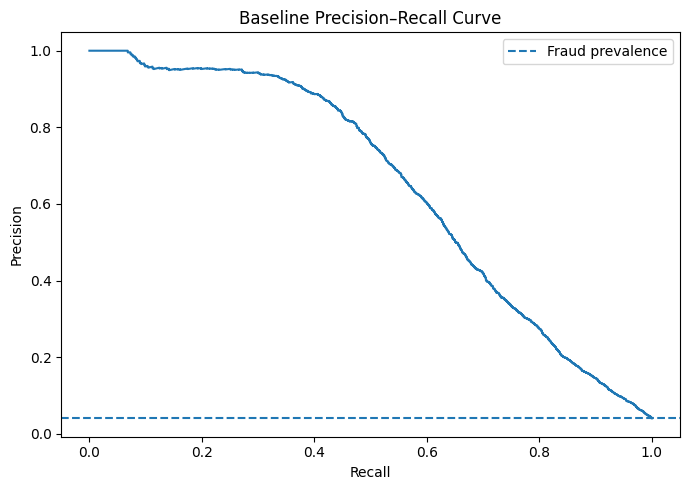

In [30]:
# Plots the precision-recall curve of the baseline model

precision, recall, thresholds = (
    precision_recall_curve(
        y_valid,
        valid_pred
    )
)

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    recall,
    precision
)

ax.axhline(
    validation_prevalence,
    linestyle="--",
    label="Fraud prevalence"
)

ax.set_title(
    "Baseline Precision–Recall Curve"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.legend()

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb02_baseline_precision_recall_curve.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

In [31]:
# Creates a results table that will be used to compare model results
# with the results of the baseline LightGBM model

baseline_table = pd.DataFrame([
    {
        "model": "Baseline LightGBM",
        "n_features": X_train.shape[1],
        "best_iteration":
            baseline_model.best_iteration_,
        "roc_auc":
            baseline_roc_auc,
        "pr_auc":
            baseline_pr_auc
    }
])

baseline_table

,model,n_features,best_iteration,roc_auc,pr_auc
0,Baseline LightGBM,434,958,0.9288,0.6466


### 4.1 Baseline Findings

The baseline LightGBM achieves **0.9288 ROC-AUC** and **0.6466 average
precision** on the internal validation period.

Validation fraud prevalence is **4.06%**, so average precision is about
**15.9× the fraud prevalence baseline**.

Early stopping selects **958 boosting iterations**.

This provides the reference model for the feature-engineering experiments that
follow.

In [32]:
zero_split_features = int(
    (
        baseline_model.feature_importances_
        == 0
    ).sum()
)

print(
    f"Input features: "
    f"{X_train.shape[1]}"
)

print(
    f"Features unused in tree splits: "
    f"{zero_split_features}"
)

Input features: 434
Features unused in tree splits: 36


## 5. Targeted Feature Engineering

A small set of interpretable transformations is tested against the baseline.
The aim is to determine whether simple domain-motivated features improve
forward validation performance without substantially increasing complexity.

### 5.1 Relative-Time Features

In [33]:
# TransactionHour is an hour-like position within the relative-day cycle
# not an actual local hour

def add_time_features(frame):
    result = frame.copy()

    result["TransactionDay"] = (
        result["TransactionDT"]
        // 86_400
    ).astype("int16")

    result["TransactionHour"] = (
        (
            result["TransactionDT"]
            % 86_400
        )
        // 3_600
    ).astype("int8")

    return result

### 5.2 Transaction-Amount Features

In [34]:
# Add amount-scale and fractional-amount representations.

def add_amount_features(frame):
    result = frame.copy()

    result["TransactionAmt_log1p"] = (
        np.log1p(
            result["TransactionAmt"]
        )
        .astype("float32")
    )

    result["TransactionAmt_fraction"] = (
        result["TransactionAmt"]
        - np.floor(
            result["TransactionAmt"]
        )
    ).astype("float32")

    return result

### 5.3 Email-Domain Features

In [35]:
def add_email_features(frame):
    result = frame.copy()

    for col in [
        "P_emaildomain",
        "R_emaildomain"
    ]:
        if col in result.columns:

            result[
                f"{col}_provider"
            ] = (
                result[col]
                .astype("string")
                .str.split(".")
                .str[0]
            )

    return result

### 5.4 Email-Domain Match

In [36]:
def add_email_match_feature(frame):
    result = frame.copy()

    result["email_domain_match"] = np.where(
        result["P_emaildomain"].isna()
        | result["R_emaildomain"].isna(),
        np.nan,
        (
            result["P_emaildomain"]
            == result["R_emaildomain"]
        ).astype("int8")
    )

    return result

### 5.5 Selected Missingness Indicators

In [37]:
MISSING_INDICATOR_COLS = [
    "D7",
    "D13",
    "dist2"
]

In [38]:
def add_selected_missing_indicators(
    frame
):
    result = frame.copy()

    for col in MISSING_INDICATOR_COLS:
        result[
            f"{col}_missing"
        ] = (
            result[col]
            .isna()
            .astype("int8")
        )

    return result

In [39]:
# Integrates the engineered features matrix

def add_engineered_features(frame):
    result = frame.copy()

    result = add_time_features(result)
    result = add_amount_features(result)
    result = add_email_features(result)
    result = add_email_match_feature(result)
    result = add_selected_missing_indicators(result)

    return result

In [40]:
X_train_fe = add_engineered_features(
    df.loc[
        train_mask,
        feature_cols
    ].copy()
)

X_valid_fe = add_engineered_features(
    df.loc[
        valid_mask,
        feature_cols
    ].copy()
)

In [41]:
# Refits categorical schema to include the new engineered categorical features

categorical_cols_fe = (
    X_train_fe
    .select_dtypes(include=["object", "string"])
    .columns
    .tolist()
)

In [42]:
category_schema_fe = fit_category_schema(
    X_train_fe,
    categorical_cols_fe
)

In [43]:
X_train_fe = apply_category_schema(
    X_train_fe,
    category_schema_fe
)

X_valid_fe = apply_category_schema(
    X_valid_fe,
    category_schema_fe
)

In [44]:
# Train the engineered feature bundle under the same
# model configuration as the baseline.

engineered_model = lgb.LGBMClassifier(
    **BASELINE_MODEL_PARAMS
)

In [45]:
engineered_model.fit(
    X_train_fe,
    y_train,
    eval_set=[
        (X_valid_fe, y_valid)
    ],
    eval_metric=[
        "auc",
        "average_precision"
    ],
    callbacks=[
        lgb.early_stopping(
        stopping_rounds=100,
        verbose=False
        ),
        lgb.log_evaluation(
        period=0
        )
    ]
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03, n_estimators=2000,
               n_jobs=-1, objective='binary', random_state=42, verbosity=-1)

In [46]:
valid_pred_fe = (
    engineered_model
    .predict_proba(
        X_valid_fe
    )[:, 1]
)

fe_roc_auc = roc_auc_score(
    y_valid,
    valid_pred_fe
)

fe_pr_auc = average_precision_score(
    y_valid,
    valid_pred_fe
)

print(
    f"All targeted features ROC-AUC: "
    f"{fe_roc_auc:.4f}"
)

print(
    f"All targeted features average precision: "
    f"{fe_pr_auc:.4f}"
)

print(
    f"Δ average precision vs baseline: "
    f"{fe_pr_auc - baseline_pr_auc:+.4f}"
)

All targeted features ROC-AUC: 0.9261
All targeted features average precision: 0.6411
Δ average precision vs baseline: -0.0055


### 5.6 Feature-Family Ablation

The complete engineered feature bundle reduces both validation ROC-AUC and
average precision.

To determine whether individual feature families still add value, the feature families are tested separately under the same model configuration and chronological split:

1. relative-time features
2. transaction-amount features
3. email-domain features
4. selected missingness indicators

The purpose is not to search for every possible feature combination, but to
check whether any individual family provides a clear improvement.

In [47]:
def add_time_only(frame):
    return add_time_features(frame)

In [48]:
def add_amount_only(frame):
    return add_amount_features(frame)

In [49]:
def add_email_only(frame):
    result = frame.copy()

    result = add_email_features(result)
    result = add_email_match_feature(result)

    return result

In [50]:
def add_missingness_only(frame):
    return add_selected_missing_indicators(frame)

In [51]:
def run_feature_ablation(
    experiment_name,
    feature_builder
):
    # Rebuild the same baseline matrices
    X_train_exp = df.loc[
        train_mask,
        feature_cols
    ].copy()

    X_valid_exp = df.loc[
        valid_mask,
        feature_cols
    ].copy()

    # Add only the requested feature family
    X_train_exp = feature_builder(
        X_train_exp
    )

    X_valid_exp = feature_builder(
        X_valid_exp
    )

    # Identify categorical features after engineering
    categorical_cols_exp = (
        X_train_exp
        .select_dtypes(
            include=["object", "string"]
        )
        .columns
        .tolist()
    )

    # Learn categorical vocabulary from training only
    category_schema_exp = fit_category_schema(
        X_train_exp,
        categorical_cols_exp
    )

    X_train_exp = apply_category_schema(
        X_train_exp,
        category_schema_exp
    )

    X_valid_exp = apply_category_schema(
        X_valid_exp,
        category_schema_exp
    )

    # Train using exactly the baseline configuration
    model = lgb.LGBMClassifier(
        **BASELINE_MODEL_PARAMS
    )

    model.fit(
        X_train_exp,
        y_train,
        eval_set=[
            (X_valid_exp, y_valid)
        ],
        eval_metric=[
            "auc",
            "average_precision"
        ],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                verbose=False
            ),
            lgb.log_evaluation(
                period=0
            )
        ]
    )

    valid_pred_exp = model.predict_proba(
        X_valid_exp
    )[:, 1]

    roc_auc = roc_auc_score(
        y_valid,
        valid_pred_exp
    )

    pr_auc = average_precision_score(
        y_valid,
        valid_pred_exp
    )

    result = {
        "model": experiment_name,
        "n_features": X_train_exp.shape[1],
        "best_iteration": model.best_iteration_,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }

    # Release large temporary matrices
    del X_train_exp
    del X_valid_exp
    del valid_pred_exp
    del model
    del category_schema_exp

    _ = gc.collect()

    return result

In [52]:
ablation_results = []

In [53]:
ablation_results.append(
    run_feature_ablation(
        "Time features only",
        add_time_only
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [54]:
ablation_results.append(
    run_feature_ablation(
        "Amount features only",
        add_amount_only
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [55]:
ablation_results.append(
    run_feature_ablation(
        "Email features only",
        add_email_only
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [56]:
ablation_results.append(
    run_feature_ablation(
        "Missingness indicators only",
        add_missingness_only
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [57]:
comparison_results = [
    {
        "model": "Baseline LightGBM",
        "n_features": X_train.shape[1],
        "best_iteration":
            baseline_model.best_iteration_,
        "roc_auc": baseline_roc_auc,
        "pr_auc": baseline_pr_auc
    },
    {
        "model": "All targeted features",
        "n_features": X_train_fe.shape[1],
        "best_iteration":
            engineered_model.best_iteration_,
        "roc_auc": fe_roc_auc,
        "pr_auc": fe_pr_auc
    },
    *ablation_results
]

ablation_table = pd.DataFrame(
    comparison_results
)

,model,n_features,best_iteration,roc_auc,pr_auc,delta_roc_auc,delta_pr_auc
0,Baseline LightGBM,434,958,0.9288,0.6466,0.0000,0.0000
1,All targeted features,444,620,0.9261,0.6411,-0.0028,-0.0055
2,Time features only,436,796,0.9276,0.6458,-0.0013,-0.0008
3,Amount features only,436,1019,0.9274,0.6493,-0.0014,0.0027
4,Email features only,437,780,0.9279,0.6437,-0.0009,-0.0029
5,Missingness indicators only,437,1087,0.9291,0.6497,0.0003,0.0031


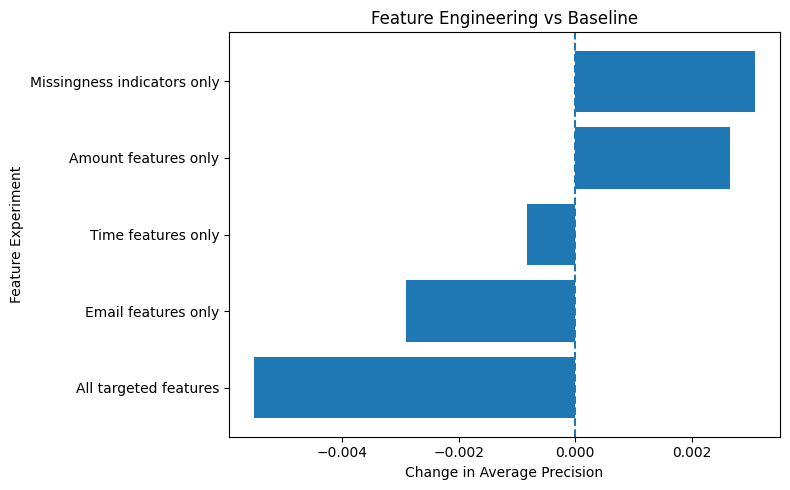

In [58]:
ablation_table["delta_roc_auc"] = (
    ablation_table["roc_auc"]
    - baseline_roc_auc
)

ablation_table["delta_pr_auc"] = (
    ablation_table["pr_auc"]
    - baseline_pr_auc
)

display(
    ablation_table
)

# Save a report-ready table with explicit metric names.
ablation_export = (
    ablation_table
    .rename(
        columns={
            "pr_auc":
                "average_precision",
            "delta_pr_auc":
                "delta_average_precision"
        }
    )
)

ablation_export.to_csv(
    TABLES_DIR
    / "nb02_feature_engineering_ablation.csv",
    index=False,
    float_format="%.6f"
)

# Visualize change in average precision relative to baseline.
ablation_plot = (
    ablation_table.loc[
        ablation_table["model"]
        != "Baseline LightGBM",
        [
            "model",
            "delta_pr_auc"
        ]
    ]
    .sort_values(
        "delta_pr_auc"
    )
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.barh(
    ablation_plot["model"],
    ablation_plot["delta_pr_auc"]
)

ax.axvline(
    0,
    linestyle="--"
)

ax.set_title(
    "Feature Engineering vs Baseline"
)

ax.set_xlabel(
    "Change in Average Precision"
)

ax.set_ylabel(
    "Feature Experiment"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb02_feature_engineering_delta_average_precision.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### 5.7 Feature-Engineering Findings

The engineered features do not provide a convincing improvement over the
original feature matrix.

The full feature bundle reduces average precision from **0.6466** to **0.6411**.
Time and email features also perform worse than the baseline.

Transaction-amount features improve average precision by **0.0027**, while the
selected missingness indicators improve it by **0.0031**. These gains are too
small to justify the added complexity.

The **original 434-feature matrix is therefore retained** for model refinement.

The unsuccessful experiments are kept to document which feature hypotheses were
tested and rejected.

In [59]:
# Memory clean-up

del X_train_fe
del X_valid_fe
del engineered_model
del valid_pred_fe
del category_schema_fe

_ = gc.collect()

## 6. Controlled LightGBM Refinement

The original 434-feature matrix is now fixed.

Four small LightGBM experiments are evaluated using the same chronological
training and validation periods. This is a limited refinement step rather than
a broad hyperparameter search.

Average precision is the primary selection metric, with ROC-AUC reported as a
secondary ranking metric. Early stopping is aligned with average precision.

In [60]:
REFERENCE_PARAMS = (
    BASELINE_MODEL_PARAMS.copy()
)

REFERENCE_PARAMS.update({
    "metric": "None",
    "n_estimators": 2500,
    "min_child_samples": 20
})

In [61]:
def run_lgbm_refinement(
    experiment_name,
    parameter_overrides=None
):
    params = REFERENCE_PARAMS.copy()

    if parameter_overrides:
        params.update(parameter_overrides)

    model = lgb.LGBMClassifier(
        **params
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[
            (X_valid, y_valid)
        ],
        eval_metric=[
            "average_precision",
            "auc"
        ],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                first_metric_only=True,
                verbose=False
            )
        ]
    )

    valid_pred = model.predict_proba(
        X_valid
    )[:, 1]

    roc_auc = roc_auc_score(
        y_valid,
        valid_pred
    )

    pr_auc = average_precision_score(
        y_valid,
        valid_pred
    )

    result = {
        "model": experiment_name,
        "n_features": X_train.shape[1],
        "best_iteration": model.best_iteration_,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }

    del model
    del valid_pred

    _ = gc.collect()

    return result

### 6.1 Refinement Experiments

In [62]:
refinement_results = []

#### Experiment 1 — PR-AUC-Aligned Baseline

In [63]:
# Check whether simply aligning early stopping with our primary metric changes the result.

refinement_results.append(
    run_lgbm_refinement(
        "PR-AUC-aligned baseline"
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


#### Experiment 2 — Higher Model Capacity

In [64]:
# Test whether additional tree capacity improves validation ranking.
# Increase num_leaves from 31 to 63.
refinement_results.append(
    run_lgbm_refinement(
        "Higher capacity",
        {
            "num_leaves": 63
        }
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


#### Experiment 3 — Stronger Regularization

In [65]:
# Test whether stronger leaf support and L1/L2
# regularization improve validation performance.

refinement_results.append(
    run_lgbm_refinement(
        "Regularized",
        {
            "min_child_samples": 50,
            "reg_alpha": 0.1,
            "reg_lambda": 1.0
        }
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


#### Experiment 4 — Explicit Class Weighting

In [66]:
# Test whether assigning higher weights to fraudulent
# transactions improves validation ranking.

n_negative = (y_train == 0).sum()
n_positive = (y_train == 1).sum()

scale_pos_weight = (
    n_negative / n_positive
)

print(
    f"Training negative-to-positive ratio: "
    f"{scale_pos_weight:.2f}"
)

Training negative-to-positive ratio: 28.59


In [67]:
refinement_results.append(
    run_lgbm_refinement(
        "Class-weighted",
        {
            "scale_pos_weight":
                scale_pos_weight
        }
    )
)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


### 6.2 Refinement Comparison

In [68]:
refinement_table = pd.DataFrame([
    {
        "model": "Original baseline",
        "n_features": X_train.shape[1],
        "best_iteration": baseline_model.best_iteration_,
        "roc_auc": baseline_roc_auc,
        "pr_auc": baseline_pr_auc
    },
    *refinement_results
])

,model,n_features,best_iteration,roc_auc,pr_auc,delta_roc_auc,delta_pr_auc
0,Original baseline,434,958,0.9288,0.6466,0.0000,0.0000
1,PR-AUC-aligned baseline,434,1558,0.9281,0.6515,-0.0007,0.0049
2,Higher capacity,434,814,0.9321,0.6584,0.0032,0.0117
3,Regularized,434,1688,0.9277,0.6548,-0.0011,0.0081
4,Class-weighted,434,787,0.9167,0.6134,-0.0121,-0.0333


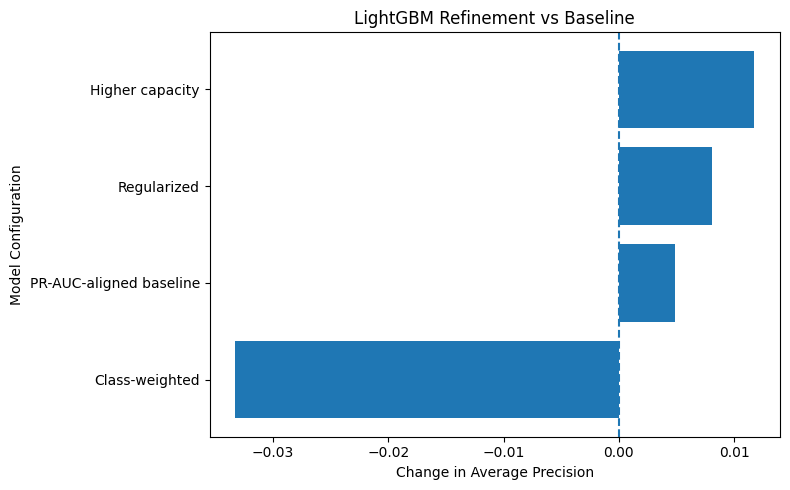

In [69]:
refinement_table["delta_roc_auc"] = (
    refinement_table["roc_auc"]
    - baseline_roc_auc
)

refinement_table["delta_pr_auc"] = (
    refinement_table["pr_auc"]
    - baseline_pr_auc
)

display(
    refinement_table
)

# Save a report-ready table with explicit metric names.
refinement_export = (
    refinement_table
    .rename(
        columns={
            "pr_auc":
                "average_precision",
            "delta_pr_auc":
                "delta_average_precision"
        }
    )
)

refinement_export.to_csv(
    TABLES_DIR
    / "nb02_model_refinement_results.csv",
    index=False,
    float_format="%.6f"
)

# Visualize change in average precision relative to baseline.
refinement_plot = (
    refinement_table.loc[
        refinement_table["model"]
        != "Original baseline",
        [
            "model",
            "delta_pr_auc"
        ]
    ]
    .sort_values(
        "delta_pr_auc"
    )
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.barh(
    refinement_plot["model"],
    refinement_plot["delta_pr_auc"]
)

ax.axvline(
    0,
    linestyle="--"
)

ax.set_title("LightGBM Refinement vs Baseline")

ax.set_xlabel("Change in Average Precision")

ax.set_ylabel("Model Configuration")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR
    / "nb02_model_refinement_delta_average_precision.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()

### 6.3 Model-Refinement Findings

Aligning early stopping with average precision raises validation average
precision from **0.6466** to **0.6515**.

The 63-leaf configuration performs best, reaching **0.9321 ROC-AUC** and
**0.6584 average precision**. Relative to the original baseline, this is an
improvement of **0.0032 ROC-AUC** and **0.0117 average precision**.

Stronger regularization reaches **0.6548 average precision** but does not
outperform the higher-capacity model.

Class weighting performs significantly worse, with **0.9167 ROC-AUC** and
**0.6134 average precision**.

The unweighted 63-leaf LightGBM is therefore selected for the next stage.

In [70]:
# Freeze the model configuration selected on internal validation.

SELECTED_MODEL_PARAMS = {
    "objective": "binary",
    "metric": "None",

    "n_estimators": 814,
    "learning_rate": 0.03,

    "num_leaves": 63,
    "max_depth": -1,
    "min_child_samples": 20,

    "colsample_bytree": 0.8,

    "reg_alpha": 0.0,
    "reg_lambda": 0.0,

    "random_state": 42,
    "n_jobs": -1
}

selected_model_params_table = (
    pd.DataFrame({
        "parameter":
            list(
                SELECTED_MODEL_PARAMS.keys()
            ),
        "value":
            list(
                SELECTED_MODEL_PARAMS.values()
            )
    })
)

selected_model_params_table.to_csv(
    TABLES_DIR
    / "nb02_selected_model_params.csv",
    index=False
)

### 6.4 Model Selection Summary

Model development stops with the 63-leaf LightGBM selected on internal
validation.

No further feature engineering or parameter tuning is performed against this
validation period.

Notebook 03 refits the selected configuration on the full development period
(days 1–127), then handles probability calibration, operating-threshold
selection, and final holdout evaluation.